In [1]:
import configparser
import os
import requests

from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyensembl import EnsemblRelease

In [ ]:
os.chdir('../')

In [2]:
ensembl = EnsemblRelease(75)

In [3]:
dataset = 'all_noHypoHyper'

In [4]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

## Load and clean MutSig2CV outputs

In [5]:
mutsig = pd.read_csv("../" + data[f'mutsig___{dataset}___out_dir'] + '/sig_genes.txt', sep='\t', engine='python', comment='#')
mutsig_RAS = pd.read_csv("../" + data[f'mutsig___{dataset}_RAS___out_dir'] + '/sig_genes.txt', sep='\t', engine='python', comment='#')
mutsig_nonRAS = pd.read_csv("../" + data[f'mutsig___{dataset}_nonRAS___out_dir'] + '/sig_genes.txt', sep='\t', engine='python', comment='#')

In [6]:
mutsig

,rank,gene,longname,codelen,nnei,nncd,nsil,nmis,nstp,nspl,nind,nnon,npat,nsite,pCV,pCL,pFN,p,q
0,1,APC,adenomatous polyposis coli,8592,7,0,13,80,641,0,334,1055,733,449,1.000000e-16,0.00001,1.00000,1.000000e-16,1.450923e-13
1,2,TP53,tumor protein p53,1314,2,0,3,504,79,5,76,664,628,204,4.588351e-16,0.00001,0.00001,1.000000e-16,1.450923e-13
2,3,FBXW7,F-box and WD repeat domain containing 7,2580,6,0,4,126,46,0,23,195,167,99,6.283482e-15,0.00001,0.00001,1.000000e-16,1.450923e-13
3,4,SMAD4,SMAD family member 4,1699,11,0,4,118,19,1,15,153,138,98,4.116163e-15,0.00001,0.00052,1.000000e-16,1.450923e-13
4,5,FAM123B,family with sequence similarity 123B,3412,20,0,6,24,60,0,22,106,104,59,3.007129e-15,0.00002,0.98310,1.000000e-16,1.450923e-13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18857,18858,AGAP8,"ArfGAP with GTPase domain, ankyrin repeat and ...",2016,73,0,1,0,0,0,0,0,0,0,1.000000e+00,NaN,NaN,1.000000e+00,1.000000e+00
18858,18859,AGAP11,ankyrin repeat and GTPase domain Arf GTPase ac...,1669,1,0,0,0,0,0,0,0,0,0,1.000000e+00,NaN,NaN,1.000000e+00,1.000000e+00
18859,18860,AG2,anterior gradient 2 homolog (Xenopus laevis),369,0,0,2,0,0,0,0,0,0,0,1.000000e+00,NaN,NaN,1.000000e+00,1.000000e+00
18860,18861,ABO,"ABO blood group (transferase A, alpha 1-3-N-ac...",1090,0,0,0,0,0,0,0,0,0,0,1.000000e+00,NaN,NaN,1.000000e+00,1.000000e+00


### MutSig2CV genes' names automatic renaming

In [7]:
all = pd.read_csv("../" + data['all_all___mutations'], sep='\t', engine='python', comment='#')
all_genes = all['Hugo_Symbol'].unique()
len(all_genes)

19010

In [8]:
all_genes_not_in_mutsig = np.setdiff1d(all_genes, mutsig['gene'].values)
len(all_genes_not_in_mutsig)

1621

In [9]:
# for each gene in mutsig if it is not in all_genes add to synonyms list
mutsig_genes_not_in_all_genes = np.setdiff1d(mutsig['gene'].values, all_genes)
mutsig_genes_not_in_all_genes

array(['A2BP1', 'A2LD1', 'AARSD1', ..., 'ZNF84', 'ZNF883', 'ZSWIM7'],
      dtype=object)

In [10]:
print('all: ', len(all_genes))
print('mutsig: ', len(mutsig['gene']))
print('all - mutsig: ', len(all_genes_not_in_mutsig))
print('mutsig - all: ', len(mutsig_genes_not_in_all_genes))

all:  19010
mutsig:  18862
all - mutsig:  1621
mutsig - all:  1473


In [11]:
def get_gene_first_name_by_synonym(gene, list1, list2):
    url_search = "https://grch37.ensembl.org/Multi/Ajax/search?q=(+{gene}%5E316+AND+species%3A%22CrossSpecies%22+)+OR+(+{gene}+AND+species%3A%22Human%22+)&fq=(++(+species%3A%22CrossSpecies%22+)++OR++(+species%3A%22Human%22+)++)&fq=feature_type%3A%22Gene%22&hl=true&hl.fl=_hr&hl.fl=content&hl.fl=description&hl.fragsize=500&start=0&rows=10"
    url_get_gene = "https://grch37.ensembl.org/Homo_sapiens/Gene/Summary?db=core;g={ID}"
    
    url_search_f = url_search.format(gene=gene)
    response_search = requests.get(url_search_f)

    genes = []
    genes_in_list1 = []
    genes_in_list2 = []

    for r in response_search.json()['result']['response']['docs']:
        gene_r = r['name']
        ID = r['id']

        url_get_gene_f = url_get_gene.format(ID=ID)
        response_get_gene = requests.get(url_get_gene_f)
        try:
            synonyms = BeautifulSoup(response_get_gene.text, 'html.parser').find(string="Gene Synonyms").find_next('p').get_text().split(', ')
        except:
            synonyms = []
        # print(synonyms)
        if (gene in synonyms) or (gene == gene_r):
            if gene_r not in genes:
                genes.append(gene_r)
                if gene_r in list1:
                    genes_in_list1.append(gene_r)
                if gene_r in list2:
                    genes_in_list2.append(gene_r)
    
    get_gene_first_name_by_synonym.i = get_gene_first_name_by_synonym.i + 1
    if(get_gene_first_name_by_synonym.i % 10 == 0):
        print(str(get_gene_first_name_by_synonym.i) + " / " + str(get_gene_first_name_by_synonym.n))
    return ' | '.join(genes), ' | '.join(genes_in_list1), ' | '.join(genes_in_list2), len(genes), len(genes_in_list1), len(genes_in_list2)

get_gene_first_name_by_synonym.i = 0
get_gene_first_name_by_synonym.n = 1473

In [12]:
synonyms = pd.read_csv("../" + data['mutsig'] + "/synonyms.csv", sep='\t')
synonyms

# synonyms = pd.DataFrame(mutsig_genes_not_in_all_genes, columns=['mutsig_name'])
# synonyms[['genes', 'genes ∈ ALL', 'genes ∈ (ALL \ MUTSIG)', '#(genes)', '#(genes ∈ ALL)', '#(genes ∈ (ALL \ MUTSIG))']] = synonyms['mutsig_name'].apply(get_gene_first_name_by_synonym, args=(all_genes, all_genes_not_in_mutsig)).apply(pd.Series)
# synonyms

,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED
0,A2BP1,RBFOX1,RBFOX1,RBFOX1,1,1,1,NaN
1,A2LD1,GGACT,GGACT,GGACT,1,1,1,NaN
2,AARSD1,AARSD1,NaN,NaN,1,0,0,NaN
3,ABO,ABO,NaN,NaN,1,0,0,NaN
4,ABP1,AOC1 | DBNL,AOC1 | DBNL,AOC1,2,2,1,NaN
...,...,...,...,...,...,...,...,...
1468,ZNF826,ZNF826P,NaN,NaN,1,0,0,NaN
1469,ZNF828,CHAMP1,CHAMP1,CHAMP1,1,1,1,NaN
1470,ZNF84,ZNF84,NaN,NaN,1,0,0,NaN
1471,ZNF883,ZNF883,NaN,NaN,1,0,0,NaN


In [13]:
# numero di geni per cui il nome usato da mutsig corrisponde a un solo gene fra quelli presenti nel database originale e non già usati da mutsig
len(synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1])

<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/3918441113.py:2: SyntaxWarning: invalid escape sequence '\ '
  len(synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1])


945

In [14]:
# di cui duplicati:
synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1][synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1]['genes ∈ (ALL \ MUTSIG)'].duplicated(keep=False)]

<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/2172760515.py:2: SyntaxWarning: invalid escape sequence '\ '
  synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1][synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1]['genes ∈ (ALL \ MUTSIG)'].duplicated(keep=False)]
/tmp/ipykernel_134858/2172760515.py:2: SyntaxWarning: invalid escape sequence '\ '
  synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1][synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1]['genes ∈ (ALL \ MUTSIG)'].duplicated(keep=False)]
/tmp/ipykernel_134858/2172760515.py:2: SyntaxWarning: invalid escape sequence '\ '
  synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1][synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1]['genes ∈ (ALL \ MUTSIG)'].d

,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED
310,C1orf84,SZT2,SZT2,SZT2,1,1,1,NaN
837,GIYD1,SLX1B | SLX1A,SLX1A,SLX1A,2,1,1,NaN
838,GIYD2,SLX1A | SLX1B,SLX1A,SLX1A,2,1,1,NaN
922,KIAA0467,SZT2,SZT2,SZT2,1,1,1,NaN


In [15]:
# numero di geni per cui il nome usato da mutsig corrisponde a un solo gene fra quelli presenti nel database originale e non già usati da mutsig
# che è anche l'unico gene restituito da ensembl presente nel database originale
len(synonyms[(synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1) & (synonyms['#(genes ∈ ALL)'] == 1)])

<>:3: SyntaxWarning: invalid escape sequence '\ '
<>:3: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/2399165246.py:3: SyntaxWarning: invalid escape sequence '\ '
  len(synonyms[(synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1) & (synonyms['#(genes ∈ ALL)'] == 1)])


933

In [16]:
# numero di geni per cui il nome usato da mutsig corrisponde a un solo gene fra quelli presenti nel database originale e non già usati da mutsig
# che è anche l'unico gene restituito da ensembl
len(synonyms[(synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1) & (synonyms['#(genes)'] == 1)])

<>:3: SyntaxWarning: invalid escape sequence '\ '
<>:3: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/2271525010.py:3: SyntaxWarning: invalid escape sequence '\ '
  len(synonyms[(synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 1) & (synonyms['#(genes)'] == 1)])


920

In [17]:
# numero di geni per cui il nome usato da mutsig non corrisponde a nessun gene fra quelli presenti nel database originale e non già usati da mutsig
len(synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 0])

<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/1426892671.py:2: SyntaxWarning: invalid escape sequence '\ '
  len(synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] == 0])


512

In [18]:
# numero di geni per cui il nome usato da mutsig corrisponde a più di un gene fra quelli presenti nel database originale e non già usati da mutsig
len(synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] > 1])

<>:2: SyntaxWarning: invalid escape sequence '\ '
<>:2: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/62183932.py:2: SyntaxWarning: invalid escape sequence '\ '
  len(synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] > 1])


16

In [19]:
# numero di geni per cui il nome usato da mutsig è anche un nome usato da ensembl ma non è presente in nel database originale
def check_contains(row):
    genes_list = row['genes'].split(' | ') if isinstance(row['genes'], str) else []
    return row['mutsig_name'] in genes_list
len(synonyms[synonyms.apply(check_contains, axis=1)])

350

In [20]:
# numero di geni per cui il nome usato da mutsig è anche il nome usato da ensembl ma non è presente in nel database originale
len(synonyms[synonyms['mutsig_name'] == synonyms['genes']])

325

In [21]:
synonyms[synonyms['mutsig_name'].str.upper().isin(all_genes)]

,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED
90,C10orf68,C10ORF68 | CCDC7,C10ORF68 | CCDC7,C10ORF68,2,2,1,C10ORF68
331,C20orf135,ABHD16B,ABHD16B,ABHD16B,1,1,1,C20ORF135
371,C2orf15,C2orf15,NaN,NaN,1,0,0,C2ORF15
468,C6orf165,C6orf165,NaN,NaN,1,0,0,C6ORF165


In [22]:
synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] > 1]

<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/289127990.py:1: SyntaxWarning: invalid escape sequence '\ '
  synonyms[synonyms['#(genes ∈ (ALL \ MUTSIG))'] > 1]


,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED
320,C20orf107,FAM209A | FAM209B,FAM209A | FAM209B,FAM209A | FAM209B,2,2,2,FAM209B
494,C7orf28A,CCZ1 | CCZ1B,CCZ1 | CCZ1B,CCZ1 | CCZ1B,2,2,2,CCZ1
495,C7orf28B,CCZ1 | CCZ1B,CCZ1 | CCZ1B,CCZ1 | CCZ1B,2,2,2,CCZ1B
562,CCBP2,ACKR2 | ACKR4,ACKR2 | ACKR4,ACKR2 | ACKR4,2,2,2,ACKR2
590,CEP110,CCP110 | CNTRL,CCP110 | CNTRL,CCP110 | CNTRL,2,2,2,CNTRL
650,DBC1,BRINP1 | CCAR2,BRINP1 | CCAR2,BRINP1 | CCAR2,2,2,2,BRINP1
716,FAM128A,MZT2A | MZT2B,MZT2A | MZT2B,MZT2A | MZT2B,2,2,2,MZT2A
717,FAM128B,MZT2A | MZT2B,MZT2A | MZT2B,MZT2A | MZT2B,2,2,2,MZT2B
739,FAM22G,NUTM2G | NUTM2F,NUTM2G | NUTM2F,NUTM2G | NUTM2F,2,2,2,NUTM2G
835,GCOM1,GCOM1 | MYZAP | POLR2M,MYZAP | POLR2M,MYZAP | POLR2M,3,2,2,MYZAP


In [23]:
manually_rename = {
    # manually
    # 'CEP110' : 'CCP110', # in CEP110 è già mappato CP110
    'C7orf28A' : 'CCZ1',
    'C7orf28B' : 'CCZ1B',
    'FAM128A' : 'MZT2A',
    'FAM128B': 'MZT2B',
    'MLL2' : 'KMT2B',
    'MLL4' : 'KMT2D',

    # -> upper case
    'C10orf68': 'C10ORF68',
    'C20orf135': 'C20ORF135', # ABHD16B
    'C2orf15': 'C2ORF15',
    'C6orf165': 'C6ORF165',

    # in the alternatives is already mapped another gene
    'C20orf107': 'FAM209B',
    'CCBP2': 'ACKR2',
    'CEP110': 'CNTRL',
    'DBC1': 'BRINP1',
    'FAM22G': 'NUTM2G',
    'GCOM1': 'MYZAP',
    'ODZ3': 'TENM3',
    'SIP1': 'GEMIN2'
}

In [24]:
synonyms['MANUALLY_RENAMED'] = synonyms['mutsig_name'].apply(lambda x: manually_rename[x] if x in manually_rename else None)
synonyms[synonyms['MANUALLY_RENAMED'].notnull()]

,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED
90,C10orf68,C10ORF68 | CCDC7,C10ORF68 | CCDC7,C10ORF68,2,2,1,C10ORF68
320,C20orf107,FAM209A | FAM209B,FAM209A | FAM209B,FAM209A | FAM209B,2,2,2,FAM209B
331,C20orf135,ABHD16B,ABHD16B,ABHD16B,1,1,1,C20ORF135
371,C2orf15,C2orf15,NaN,NaN,1,0,0,C2ORF15
468,C6orf165,C6orf165,NaN,NaN,1,0,0,C6ORF165
494,C7orf28A,CCZ1 | CCZ1B,CCZ1 | CCZ1B,CCZ1 | CCZ1B,2,2,2,CCZ1
495,C7orf28B,CCZ1 | CCZ1B,CCZ1 | CCZ1B,CCZ1 | CCZ1B,2,2,2,CCZ1B
562,CCBP2,ACKR2 | ACKR4,ACKR2 | ACKR4,ACKR2 | ACKR4,2,2,2,ACKR2
590,CEP110,CCP110 | CNTRL,CCP110 | CNTRL,CCP110 | CNTRL,2,2,2,CNTRL
650,DBC1,BRINP1 | CCAR2,BRINP1 | CCAR2,BRINP1 | CCAR2,2,2,2,BRINP1


In [25]:
synonyms.to_csv("../" + data['mutsig'] + "/synonyms.csv", sep='\t', index=False)

In [26]:
synonyms[synonyms.duplicated(subset='genes ∈ (ALL \ MUTSIG)', keep=False) & synonyms['#(genes ∈ (ALL \ MUTSIG))']>0]

<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/2839062151.py:1: SyntaxWarning: invalid escape sequence '\ '
  synonyms[synonyms.duplicated(subset='genes ∈ (ALL \ MUTSIG)', keep=False) & synonyms['#(genes ∈ (ALL \ MUTSIG))']>0]
/tmp/ipykernel_134858/2839062151.py:1: SyntaxWarning: invalid escape sequence '\ '
  synonyms[synonyms.duplicated(subset='genes ∈ (ALL \ MUTSIG)', keep=False) & synonyms['#(genes ∈ (ALL \ MUTSIG))']>0]


,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED
310,C1orf84,SZT2,SZT2,SZT2,1,1,1,None
837,GIYD1,SLX1B | SLX1A,SLX1A,SLX1A,2,1,1,None
838,GIYD2,SLX1A | SLX1B,SLX1A,SLX1A,2,1,1,None
922,KIAA0467,SZT2,SZT2,SZT2,1,1,1,None


In [27]:
synonyms['choosen'] = synonyms.apply(lambda x: x['MANUALLY_RENAMED'] if x['MANUALLY_RENAMED'] else (x['genes ∈ (ALL \ MUTSIG)'] if x['#(genes ∈ (ALL \ MUTSIG))'] == 1 else None), axis=1)
# change a value in the table
synonyms.loc[synonyms['mutsig_name'].isin(['GIYD1', 'GIYD2', 'C1orf84']), 'choosen'] = None
synonyms

<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
<>:1: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_134858/2019397251.py:1: SyntaxWarning: invalid escape sequence '\ '
  synonyms['choosen'] = synonyms.apply(lambda x: x['MANUALLY_RENAMED'] if x['MANUALLY_RENAMED'] else (x['genes ∈ (ALL \ MUTSIG)'] if x['#(genes ∈ (ALL \ MUTSIG))'] == 1 else None), axis=1)
/tmp/ipykernel_134858/2019397251.py:1: SyntaxWarning: invalid escape sequence '\ '
  synonyms['choosen'] = synonyms.apply(lambda x: x['MANUALLY_RENAMED'] if x['MANUALLY_RENAMED'] else (x['genes ∈ (ALL \ MUTSIG)'] if x['#(genes ∈ (ALL \ MUTSIG))'] == 1 else None), axis=1)


,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED,choosen
0,A2BP1,RBFOX1,RBFOX1,RBFOX1,1,1,1,None,RBFOX1
1,A2LD1,GGACT,GGACT,GGACT,1,1,1,None,GGACT
2,AARSD1,AARSD1,NaN,NaN,1,0,0,None,None
3,ABO,ABO,NaN,NaN,1,0,0,None,None
4,ABP1,AOC1 | DBNL,AOC1 | DBNL,AOC1,2,2,1,None,AOC1
...,...,...,...,...,...,...,...,...,...
1468,ZNF826,ZNF826P,NaN,NaN,1,0,0,None,None
1469,ZNF828,CHAMP1,CHAMP1,CHAMP1,1,1,1,None,CHAMP1
1470,ZNF84,ZNF84,NaN,NaN,1,0,0,None,None
1471,ZNF883,ZNF883,NaN,NaN,1,0,0,None,None


In [28]:
rename_map = synonyms[synonyms['choosen'].notna()][['mutsig_name', 'choosen']].set_index('mutsig_name').to_dict()['choosen']

In [29]:
not_renamed_genes = synonyms[synonyms['choosen'].isna()]['mutsig_name'].values
len(not_renamed_genes)

515

In [30]:
# rename genes in mutsig/mutsig_RAS/mutsig_nonRAS
mutsig['gene'] = mutsig['gene'].replace(rename_map)
mutsig_RAS['gene'] = mutsig_RAS['gene'].replace(rename_map)
mutsig_nonRAS['gene'] = mutsig_nonRAS['gene'].replace(rename_map)

In [31]:
assert mutsig['p'].isna().sum() == 0
assert mutsig['q'].isna().sum() == 0
assert mutsig['gene'].isna().sum() == 0
assert (mutsig['gene'] == '').sum() == 0

assert mutsig_RAS['p'].isna().sum() == 0
assert mutsig_RAS['q'].isna().sum() == 0
assert mutsig_RAS['gene'].isna().sum() == 0
assert (mutsig_RAS['gene'] == '').sum() == 0

assert mutsig_nonRAS['p'].isna().sum() == 0
assert mutsig_nonRAS['q'].isna().sum() == 0
assert mutsig_nonRAS['gene'].isna().sum() == 0
assert (mutsig_nonRAS['gene'] == '').sum() == 0

assert mutsig.duplicated(subset='gene').sum() == 0
assert mutsig_RAS.duplicated(subset='gene').sum() == 0
assert mutsig_nonRAS.duplicated(subset='gene').sum() == 0

In [32]:
synonyms.to_csv("../" + data['mutsig'] + "/synonyms_final.csv", sep='\t', index=False)

## p-value analysis

In [33]:
pv_qfreq = 0.01

In [34]:
# create dataframes containing p values and the number of genes with p-value lower than that
numGenes_pvLower = pd.DataFrame(
    [(i, len(mutsig.loc[mutsig['p'] <= i, 'gene'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(mutsig_RAS.loc[mutsig_RAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(mutsig_nonRAS.loc[mutsig_nonRAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)

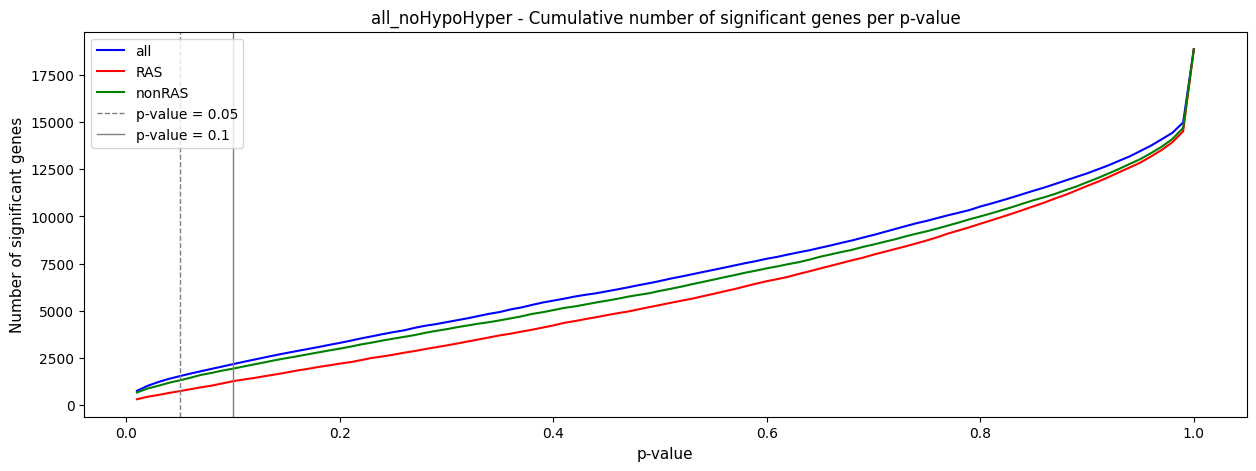

In [35]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes per p-value')
plt.plot(numGenes_pvLower.set_index('p-value'), label='all', color='blue')
plt.plot(numGenes_pvLower_RAS.set_index('p-value'), label='RAS', color='red')
plt.plot(numGenes_pvLower_nonRAS.set_index('p-value'), label='nonRAS', color='green')
plt.axvline(x=0.05, color='grey', linestyle='--', linewidth=1, label='p-value = 0.05')
plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='p-value = 0.1')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_mutsig_cumulativeNumSignificantGenes_perPV.png')
plt.show()

In [36]:
numGenes_pvLower.head(10)

,p-value,numGenes
0,0.01,765
1,0.02,1030
2,0.03,1230
3,0.04,1400
4,0.05,1539
5,0.06,1677
6,0.07,1804
7,0.08,1929
8,0.09,2051
9,0.10,2178


In [37]:
genes_all_pv01 = mutsig.loc[mutsig['p'] < 0.1, 'gene']
genes_all_pv005 = mutsig.loc[mutsig['p'] < 0.05, 'gene']

genes_RAS_pv01 = mutsig_RAS.loc[mutsig_RAS['p'] < 0.1, 'gene']
genes_RAS_pv005 = mutsig_RAS.loc[mutsig_RAS['p'] < 0.05, 'gene']

genes_nonRAS_pv01 = mutsig_nonRAS.loc[mutsig_nonRAS['p'] < 0.1, 'gene']
genes_nonRAS_pv005 = mutsig_nonRAS.loc[mutsig_nonRAS['p'] < 0.05, 'gene']

In [38]:
print('all:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t\t' + str(genes_all_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t\t' + str(genes_all_pv005.count()))
print()
print('RAS:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t\t' + str(genes_RAS_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t\t' + str(genes_RAS_pv005.count()))
print()
print('nonRAS:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t\t' + str(genes_nonRAS_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t\t' + str(genes_nonRAS_pv005.count()))

all:
Number of significant genes with p-value < 0.1:					2178
Number of significant genes with p-value < 0.05:				1539

RAS:
Number of significant genes with p-value < 0.1:					1276
Number of significant genes with p-value < 0.05:				748

nonRAS:
Number of significant genes with p-value < 0.1:					1940
Number of significant genes with p-value < 0.05:				1319


In [39]:
commonGenes_all_RAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005))
commonGenes_all_RAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01))

commonGenes_all_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_all_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_RAS_nonRAS_pv005 = set(genes_RAS_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_RAS_nonRAS_pv01 = set(genes_RAS_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_all_RAS_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005)).intersection(set(genes_nonRAS_pv005))
commonGenes_all_RAS_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01)).intersection(set(genes_nonRAS_pv01))

In [40]:
print('all ∩ RAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_RAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_RAS_pv01)))
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv01)))
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv01)))
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01)))

all ∩ RAS:
Number of common significant genes with p-value < 0.05:	395
Number of common significant genes with p-value < 0.1:	639

all ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	936
Number of common significant genes with p-value < 0.1:	1357

RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	218
Number of common significant genes with p-value < 0.1:	368

all ∩ RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	216
Number of common significant genes with p-value < 0.1:	356


In [41]:
genes_RAS_notIn_nonRAS_pv005 = set(genes_RAS_pv005).difference(set(genes_nonRAS_pv005))
genes_RAS_notIn_nonRAS_pv01 = set(genes_RAS_pv01).difference(set(genes_nonRAS_pv01))

genes_nonRAS_notIn_RAS_pv005 = set(genes_nonRAS_pv005).difference(set(genes_RAS_pv005))
genes_nonRAS_notIn_RAS_pv01 = set(genes_nonRAS_pv01).difference(set(genes_RAS_pv01))

nonCommonGenes_RAS_nonRAS_pv005 = genes_RAS_notIn_nonRAS_pv005.union(genes_nonRAS_notIn_RAS_pv005)
nonCommonGenes_RAS_nonRAS_pv01 = genes_RAS_notIn_nonRAS_pv01.union(genes_nonRAS_notIn_RAS_pv01)

In [42]:
print('RAS \\ nonRAS:')
print('Number of significant genes with p-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv005)))
print('Number of significant genes with p-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv01)))
print()
print('nonRAS \\ RAS:')
print('Number of significant genes with p-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv005)))
print('Number of significant genes with p-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv01)))
print()
print('RAS Δ nonRAS:')
print('Number of significant genes with p-value < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005)))
print('Number of significant genes with p-value < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01)))

RAS \ nonRAS:
Number of significant genes with p-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:		530
Number of significant genes with p-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:		908

nonRAS \ RAS:
Number of significant genes with p-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:		1101
Number of significant genes with p-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:		1572

RAS Δ nonRAS:
Number of significant genes with p-value < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:	1631
Number of significant genes with p-value < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:	2480


In [43]:
genes_RAS_notIn_nonRAS_pv005

{'A2M',
 'ABCA3',
 'ABCD2',
 'ABCF3',
 'ACTA2',
 'ACTB',
 'ACTG2',
 'ADAM18',
 'ADAM7',
 'ADAMTS3',
 'ADCY4',
 'AFF4',
 'AGBL5',
 'AGMO',
 'AGT',
 'AHR',
 'AIMP1',
 'AKAP9',
 'AMD1',
 'AMPD3',
 'AP2S1',
 'APBB1',
 'APOE',
 'AQP11',
 'ARHGEF6',
 'ARL11',
 'ARMCX1',
 'ARPC1B',
 'AS3MT',
 'ASPHD1',
 'ASPN',
 'ATF5',
 'ATF7IP',
 'ATRIP',
 'ATXN1',
 'B4GALT3',
 'BCOR',
 'BDP1',
 'BIRC3',
 'BIRC6',
 'BMP10',
 'BPIFB2',
 'C10orf88',
 'C11orf63',
 'C14orf180',
 'C19orf38',
 'C19orf70',
 'C20orf27',
 'C3orf38',
 'C5orf49',
 'C6orf136',
 'C9orf91',
 'CACNG3',
 'CALD1',
 'CANT1',
 'CAPN9',
 'CAPZA2',
 'CBX1',
 'CCAR2',
 'CCDC28B',
 'CCDC92',
 'CCKAR',
 'CCNL2',
 'CD4',
 'CD6',
 'CD8A',
 'CDCA8',
 'CDH10',
 'CDH2',
 'CDKL4',
 'CEACAM19',
 'CENPI',
 'CEP290',
 'CERS5',
 'CHTOP',
 'CLCN1',
 'CLDN10',
 'CLDN18',
 'CLPTM1',
 'CMA1',
 'CNKSR1',
 'CNKSR3',
 'COL20A1',
 'CORIN',
 'COX7A2',
 'CPA2',
 'CPN1',
 'CPT1B',
 'CREB3',
 'CRYBB1',
 'CSNK1G3',
 'CTDSP2',
 'CTLA4',
 'CTNND1',
 'CXCR1',
 'CYP2U1',
 '

In [44]:
genes_RAS_notIn_nonRAS_pv01

{'A2ML1',
 'AADACL4',
 'ABCA3',
 'ABCD2',
 'ABCF3',
 'ABCG8',
 'ABHD2',
 'ABI3',
 'ACADL',
 'ACOXL',
 'ACTA2',
 'ACTB',
 'ACTG2',
 'ACTR1B',
 'ADAM10',
 'ADAM18',
 'ADAM7',
 'ADAMTSL4',
 'ADCY4',
 'ADIPOR2',
 'ADRBK1',
 'AFF4',
 'AGMO',
 'AGT',
 'AHCYL1',
 'AHR',
 'AIM2',
 'AIMP1',
 'AKAP9',
 'ALDH16A1',
 'ALG10B',
 'ALOX15',
 'AMD1',
 'AMPD3',
 'ANKDD1A',
 'ANLN',
 'AP2S1',
 'APBB1',
 'APLP1',
 'APOE',
 'AQP11',
 'ARHGAP17',
 'ARHGAP25',
 'ARHGAP27',
 'ARHGEF6',
 'ARL11',
 'ARL13A',
 'ARMC3',
 'ARMCX1',
 'ARMCX5',
 'ARNTL2',
 'ARPC1B',
 'ARSI',
 'AS3MT',
 'ASAP2',
 'ASPHD1',
 'ASPHD2',
 'ATAD3B',
 'ATF5',
 'ATF7IP',
 'ATG12',
 'ATP6V1E2',
 'ATXN1',
 'B4GALT3',
 'BCL7A',
 'BCL7B',
 'BDKRB1',
 'BDNF',
 'BDP1',
 'BEST3',
 'BIRC3',
 'BIRC6',
 'BMX',
 'BNIPL',
 'BPIFA3',
 'BPIFB2',
 'BTBD9',
 'C10orf88',
 'C11orf63',
 'C12orf50',
 'C14orf166B',
 'C14orf180',
 'C16orf59',
 'C17orf53',
 'C19orf38',
 'C19orf70',
 'C1orf127',
 'C20orf27',
 'C3orf38',
 'C5orf49',
 'C6orf136',
 'C6orf211',
 'C9o

## q-value analysis

In [45]:
qv_qfreq = 0.01

In [46]:
# create dataframes containing q values and the number of genes with q-value lower than that
numGenes_qvLower = pd.DataFrame(
    [(i, len(mutsig.loc[mutsig['q'] <= i, 'gene'])) for i in np.clip(np.arange(qv_qfreq, 1+qv_qfreq, qv_qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)
numGenes_qvLower_RAS = pd.DataFrame(
    [(i, len(mutsig_RAS.loc[mutsig_RAS['q'] <= i, 'gene'])) for i in np.clip(np.arange(qv_qfreq, 1+qv_qfreq, qv_qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)
numGenes_qvLower_nonRAS = pd.DataFrame(
    [(i, len(mutsig_nonRAS.loc[mutsig_nonRAS['q'] <= i, 'gene'])) for i in np.clip(np.arange(qv_qfreq, 1+qv_qfreq, qv_qfreq), a_min=0, a_max=1)],
    columns=['q-value', 'numGenes']
)

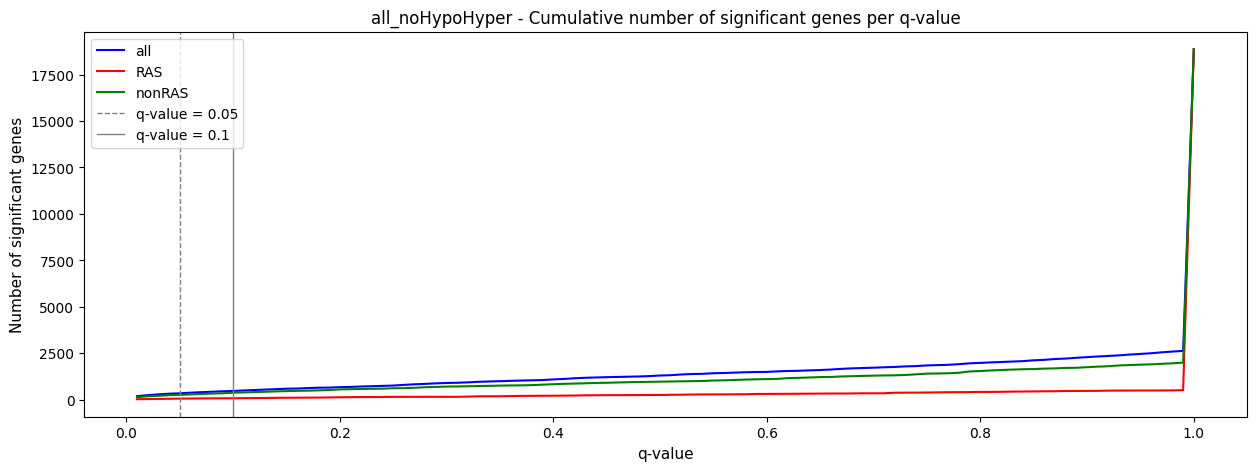

In [47]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes per q-value')
plt.plot(numGenes_qvLower.set_index('q-value'), label='all', color='blue')
plt.plot(numGenes_qvLower_RAS.set_index('q-value'), label='RAS', color='red')
plt.plot(numGenes_qvLower_nonRAS.set_index('q-value'), label='nonRAS', color='green')
plt.axvline(x=0.05, color='grey', linestyle='--', linewidth=1, label='q-value = 0.05')
plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='q-value = 0.1')
plt.xlabel('q-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_mutsig_cumulativeNumSignificantGenes_perQV.png')
plt.show()

In [48]:
numGenes_qvLower.head(10)

,q-value,numGenes
0,0.01,196
1,0.02,253
2,0.03,296
3,0.04,331
4,0.05,351
5,0.06,385
6,0.07,413
7,0.08,436
8,0.09,462
9,0.10,478


In [49]:
genes_all_qv1 = mutsig.loc[mutsig['q'] < 1, 'gene']
genes_all_qv01 = mutsig.loc[mutsig['q'] < 0.1, 'gene']
genes_all_qv005 = mutsig.loc[mutsig['q'] < 0.05, 'gene']

genes_RAS_qv1 = mutsig_RAS.loc[mutsig_RAS['q'] < 1, 'gene']
genes_RAS_qv01 = mutsig_RAS.loc[mutsig_RAS['q'] < 0.1, 'gene']
genes_RAS_qv005 = mutsig_RAS.loc[mutsig_RAS['q'] < 0.05, 'gene']

genes_nonRAS_qv1 = mutsig_nonRAS.loc[mutsig_nonRAS['q'] < 1, 'gene']
genes_nonRAS_qv01 = mutsig_nonRAS.loc[mutsig_nonRAS['q'] < 0.1, 'gene']
genes_nonRAS_qv005 = mutsig_nonRAS.loc[mutsig_nonRAS['q'] < 0.05, 'gene']

In [50]:
print('all:')
print('Number of significant genes with q-value < 1:\t\t\t\t\t' + str(genes_all_qv1.count()))
print('Number of significant genes with q-value < 0.1:\t\t\t\t\t' + str(genes_all_qv01.count()))
print('Number of significant genes with q-value < 0.05:\t\t\t\t' + str(genes_all_qv005.count()))
print()
print('RAS:')
print('Number of significant genes with q-value < 1:\t\t\t\t\t' + str(genes_RAS_qv1.count()))
print('Number of significant genes with q-value < 0.1:\t\t\t\t\t' + str(genes_RAS_qv01.count()))
print('Number of significant genes with q-value < 0.05:\t\t\t\t' + str(genes_RAS_qv005.count()))
print()
print('nonRAS:')
print('Number of significant genes with q-value < 1:\t\t\t\t\t' + str(genes_nonRAS_qv1.count()))
print('Number of significant genes with q-value < 0.1:\t\t\t\t\t' + str(genes_nonRAS_qv01.count()))
print('Number of significant genes with q-value < 0.05:\t\t\t\t' + str(genes_nonRAS_qv005.count()))

all:
Number of significant genes with q-value < 1:					2675
Number of significant genes with q-value < 0.1:					478
Number of significant genes with q-value < 0.05:				351

RAS:
Number of significant genes with q-value < 1:					526
Number of significant genes with q-value < 0.1:					86
Number of significant genes with q-value < 0.05:				66

nonRAS:
Number of significant genes with q-value < 1:					2028
Number of significant genes with q-value < 0.1:					386
Number of significant genes with q-value < 0.05:				268


In [51]:
commonGenes_all_RAS_qv005 = set(genes_all_qv005).intersection(set(genes_RAS_qv005))
commonGenes_all_RAS_qv01 = set(genes_all_qv01).intersection(set(genes_RAS_qv01))
commonGenes_all_RAS_qv1 = set(genes_all_qv1).intersection(set(genes_RAS_qv1))

commonGenes_all_nonRAS_qv005 = set(genes_all_qv005).intersection(set(genes_nonRAS_qv005))
commonGenes_all_nonRAS_qv01 = set(genes_all_qv01).intersection(set(genes_nonRAS_qv01))
commonGenes_all_nonRAS_qv1 = set(genes_all_qv1).intersection(set(genes_nonRAS_qv1))

commonGenes_RAS_nonRAS_qv005 = set(genes_RAS_qv005).intersection(set(genes_nonRAS_qv005))
commonGenes_RAS_nonRAS_qv01 = set(genes_RAS_qv01).intersection(set(genes_nonRAS_qv01))
commonGenes_RAS_nonRAS_qv1 = set(genes_RAS_qv1).intersection(set(genes_nonRAS_qv1))

commonGenes_all_RAS_nonRAS_qv005 = set(genes_all_qv005).intersection(set(genes_RAS_qv005)).intersection(set(genes_nonRAS_qv005))
commonGenes_all_RAS_nonRAS_qv01 = set(genes_all_qv01).intersection(set(genes_RAS_qv01)).intersection(set(genes_nonRAS_qv01))
commonGenes_all_RAS_nonRAS_qv1 = set(genes_all_qv1).intersection(set(genes_RAS_qv1)).intersection(set(genes_nonRAS_qv1))

In [52]:
print('all ∩ RAS:')
print('Number of common significant genes with q-value < 0.05:\t' + str(len(commonGenes_all_RAS_qv005)))
print('Number of common significant genes with q-value < 0.1:\t' + str(len(commonGenes_all_RAS_qv01)))
print('Number of common significant genes with q-value < 1:\t' + str(len(commonGenes_all_RAS_qv1)))
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with q-value < 0.05:\t' + str(len(commonGenes_all_nonRAS_qv005)))
print('Number of common significant genes with q-value < 0.1:\t' + str(len(commonGenes_all_nonRAS_qv01)))
print('Number of common significant genes with q-value < 1:\t' + str(len(commonGenes_all_nonRAS_qv1)))
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with q-value < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_qv005)))
print('Number of common significant genes with q-value < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_qv01)))
print('Number of common significant genes with q-value < 1:\t' + str(len(commonGenes_RAS_nonRAS_qv1)))
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with q-value < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_qv005)))
print('Number of common significant genes with q-value < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_qv01)))
print('Number of common significant genes with q-value < 1:\t' + str(len(commonGenes_all_RAS_nonRAS_qv1)))

all ∩ RAS:
Number of common significant genes with q-value < 0.05:	55
Number of common significant genes with q-value < 0.1:	66
Number of common significant genes with q-value < 1:	397

all ∩ nonRAS:
Number of common significant genes with q-value < 0.05:	196
Number of common significant genes with q-value < 0.1:	287
Number of common significant genes with q-value < 1:	1532

RAS ∩ nonRAS:
Number of common significant genes with q-value < 0.05:	35
Number of common significant genes with q-value < 0.1:	44
Number of common significant genes with q-value < 1:	219

all ∩ RAS ∩ nonRAS:
Number of common significant genes with q-value < 0.05:	35
Number of common significant genes with q-value < 0.1:	44
Number of common significant genes with q-value < 1:	218


In [53]:
genes_RAS_notIn_nonRAS_qv005 = set(genes_RAS_qv005).difference(set(genes_nonRAS_qv005))
genes_RAS_notIn_nonRAS_qv01 = set(genes_RAS_qv01).difference(set(genes_nonRAS_qv01))
genes_RAS_notIn_nonRAS_qv1 = set(genes_RAS_qv1).difference(set(genes_nonRAS_qv1))

genes_nonRAS_notIn_RAS_qv005 = set(genes_nonRAS_qv005).difference(set(genes_RAS_qv005))
genes_nonRAS_notIn_RAS_qv01 = set(genes_nonRAS_qv01).difference(set(genes_RAS_qv01))
genes_nonRAS_notIn_RAS_qv1 = set(genes_nonRAS_qv1).difference(set(genes_RAS_qv1))

nonCommonGenes_RAS_nonRAS_qv005 = genes_RAS_notIn_nonRAS_qv005.union(genes_nonRAS_notIn_RAS_qv005)
nonCommonGenes_RAS_nonRAS_qv01 = genes_RAS_notIn_nonRAS_qv01.union(genes_nonRAS_notIn_RAS_qv01)
nonCommonGenes_RAS_nonRAS_qv1 = genes_RAS_notIn_nonRAS_qv1.union(genes_nonRAS_notIn_RAS_qv1)

In [54]:
print('RAS \\ nonRAS:')
print('Number of significant genes with q-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_qv005)))
print('Number of significant genes with q-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_qv01)))
print('Number of significant genes with q-value < 1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_qv1)))
print()
print('nonRAS \\ RAS:')
print('Number of significant genes with q-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_qv005)))
print('Number of significant genes with q-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_qv01)))
print('Number of significant genes with q-value < 1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_qv1)))
print()
print('RAS Δ nonRAS:')
print('Number of significant genes with q-value < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_qv005)))
print('Number of significant genes with q-value < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_qv01)))
print('Number of significant genes with q-value < 1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_qv1)))

RAS \ nonRAS:
Number of significant genes with q-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:		31
Number of significant genes with q-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:		42
Number of significant genes with q-value < 1 in RAS-mutated patients but not in non RAS-mutated patients:		307

nonRAS \ RAS:
Number of significant genes with q-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:		233
Number of significant genes with q-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:		342
Number of significant genes with q-value < 1 in non RAS-mutated patients but not in RAS-mutated patients:		1809

RAS Δ nonRAS:
Number of significant genes with q-value < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:	264
Number of significant genes with q-value < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:	384
Number of significant genes with q-value

In [55]:
genes_RAS_notIn_nonRAS_qv005

{'ACVR1B',
 'DHX8',
 'DNAH12',
 'E2F5',
 'ELF3',
 'ERBB2',
 'FGFBP1',
 'HDLBP',
 'HIST1H1E',
 'ING1',
 'KIF9',
 'KRAS',
 'MCAM',
 'MRI1',
 'NRAS',
 'PLK1',
 'PSD',
 'RAD51AP2',
 'RAG2',
 'SLC35G1',
 'SMAD2',
 'STAT5B',
 'TCF12',
 'TCF7',
 'TDG',
 'TICAM1',
 'TRIM46',
 'UHRF1BP1',
 'ZBTB5',
 'ZC3H18',
 'ZDHHC7'}

In [56]:
genes_RAS_notIn_nonRAS_qv01

{'ACVR1B',
 'ALPK2',
 'ATRIP',
 'CLPTM1',
 'CTLA4',
 'DHX8',
 'DNAH12',
 'E2F5',
 'ELF3',
 'ERBB2',
 'ERBB3',
 'FGFBP1',
 'GNAZ',
 'GPA33',
 'HIST1H1E',
 'ING1',
 'KIF9',
 'KRAS',
 'LRPPRC',
 'MCAM',
 'MTOR',
 'NRAS',
 'NUP35',
 'OXSM',
 'PLK1',
 'PSD',
 'RAD51AP2',
 'RAG2',
 'SLC35G1',
 'SLCO5A1',
 'STAT5B',
 'TCF12',
 'TCF7',
 'TDG',
 'TICAM1',
 'TNRC6B',
 'TRIM46',
 'UHRF1BP1',
 'ZBTB5',
 'ZC3H18',
 'ZDHHC7',
 'ZFPL1'}

In [57]:
genes_RAS_notIn_nonRAS_qv1

{'ACTA2',
 'ACTB',
 'ACTG2',
 'ADAM18',
 'ADAM7',
 'AGMO',
 'AGT',
 'AHR',
 'AKAP9',
 'AMD1',
 'AMPD3',
 'APOE',
 'ARPC1B',
 'ATF7IP',
 'ATXN1',
 'B4GALT3',
 'BDP1',
 'BIRC3',
 'BIRC6',
 'BPIFB2',
 'C10orf88',
 'C11orf63',
 'C3orf38',
 'C5orf49',
 'C9orf91',
 'CACNG3',
 'CALD1',
 'CANT1',
 'CAPN9',
 'CBX1',
 'CCDC92',
 'CCKAR',
 'CCNL2',
 'CD6',
 'CD8A',
 'CDH10',
 'CDKL4',
 'CEACAM19',
 'CHTOP',
 'CLCN1',
 'CLDN10',
 'CLPTM1',
 'CNKSR3',
 'COL20A1',
 'CORIN',
 'COX7A2',
 'CPN1',
 'CREB3',
 'CTDSP2',
 'CTLA4',
 'CTNND1',
 'DAK',
 'DDC',
 'DENND2D',
 'DHX8',
 'DIRAS1',
 'DLK1',
 'DNAJC10',
 'DPYSL2',
 'DYRK3',
 'DYSF',
 'E2F5',
 'EDF1',
 'EDRF1',
 'EEA1',
 'EGF',
 'EI24',
 'ELK3',
 'EML1',
 'ENOX1',
 'EQTN',
 'ERBB2',
 'ERBB3',
 'ETNK1',
 'FAIM2',
 'FAM129B',
 'FAM135A',
 'FCRL3',
 'FGD2',
 'FLG2',
 'FSD2',
 'FUOM',
 'FYN',
 'GALNT11',
 'GCG',
 'GCKR',
 'GDF9',
 'GGA3',
 'GIMAP1',
 'GIPC3',
 'GLT8D2',
 'GPA33',
 'GPR20',
 'GPRC5D',
 'GPX5',
 'GRID1',
 'GRINA',
 'GRM8',
 'GZMK',
 'HAPLN1

## p-value and q-value analisys

In [58]:
# all ∩ RAS
commonGenes_all_RAS_pv01_qv1 = commonGenes_all_RAS_pv01.intersection(commonGenes_all_RAS_qv1)
commonGenes_all_RAS_pv01_qv01 = commonGenes_all_RAS_pv01.intersection(commonGenes_all_RAS_qv01)
commonGenes_all_RAS_pv01_qv005 = commonGenes_all_RAS_pv01.intersection(commonGenes_all_RAS_qv005)

commonGenes_all_RAS_pv005_qv1 = commonGenes_all_RAS_pv005.intersection(commonGenes_all_RAS_qv1)
commonGenes_all_RAS_pv005_qv01 = commonGenes_all_RAS_pv005.intersection(commonGenes_all_RAS_qv01)
commonGenes_all_RAS_pv005_qv005 = commonGenes_all_RAS_pv005.intersection(commonGenes_all_RAS_qv005)

# all ∩ nonRAS
commonGenes_all_nonRAS_pv01_qv1 = commonGenes_all_nonRAS_pv01.intersection(commonGenes_all_nonRAS_qv1)
commonGenes_all_nonRAS_pv01_qv01 = commonGenes_all_nonRAS_pv01.intersection(commonGenes_all_nonRAS_qv01)
commonGenes_all_nonRAS_pv01_qv005 = commonGenes_all_nonRAS_pv01.intersection(commonGenes_all_nonRAS_qv005)

commonGenes_all_nonRAS_pv005_qv1 = commonGenes_all_nonRAS_pv005.intersection(commonGenes_all_nonRAS_qv1)
commonGenes_all_nonRAS_pv005_qv01 = commonGenes_all_nonRAS_pv005.intersection(commonGenes_all_nonRAS_qv01)
commonGenes_all_nonRAS_pv005_qv005 = commonGenes_all_nonRAS_pv005.intersection(commonGenes_all_nonRAS_qv005)

# RAS ∩ nonRAS
commonGenes_RAS_nonRAS_pv01_qv1 = commonGenes_RAS_nonRAS_pv01.intersection(commonGenes_RAS_nonRAS_qv1)
commonGenes_RAS_nonRAS_pv01_qv01 = commonGenes_RAS_nonRAS_pv01.intersection(commonGenes_RAS_nonRAS_qv01)
commonGenes_RAS_nonRAS_pv01_qv005 = commonGenes_RAS_nonRAS_pv01.intersection(commonGenes_RAS_nonRAS_qv005)

commonGenes_RAS_nonRAS_pv005_qv1 = commonGenes_RAS_nonRAS_pv005.intersection(commonGenes_RAS_nonRAS_qv1)
commonGenes_RAS_nonRAS_pv005_qv01 = commonGenes_RAS_nonRAS_pv005.intersection(commonGenes_RAS_nonRAS_qv01)
commonGenes_RAS_nonRAS_pv005_qv005 = commonGenes_RAS_nonRAS_pv005.intersection(commonGenes_RAS_nonRAS_qv005)

# all ∩ RAS ∩ nonRAS
commonGenes_all_RAS_nonRAS_pv01_qv1 = commonGenes_all_RAS_nonRAS_pv01.intersection(commonGenes_all_RAS_nonRAS_qv1)
commonGenes_all_RAS_nonRAS_pv01_qv01 = commonGenes_all_RAS_nonRAS_pv01.intersection(commonGenes_all_RAS_nonRAS_qv01)
commonGenes_all_RAS_nonRAS_pv01_qv005 = commonGenes_all_RAS_nonRAS_pv01.intersection(commonGenes_all_RAS_nonRAS_qv005)

commonGenes_all_RAS_nonRAS_pv005_qv1 = commonGenes_all_RAS_nonRAS_pv005.intersection(commonGenes_all_RAS_nonRAS_qv1)
commonGenes_all_RAS_nonRAS_pv005_qv01 = commonGenes_all_RAS_nonRAS_pv005.intersection(commonGenes_all_RAS_nonRAS_qv01)
commonGenes_all_RAS_nonRAS_pv005_qv005 = commonGenes_all_RAS_nonRAS_pv005.intersection(commonGenes_all_RAS_nonRAS_qv005)

In [59]:
print('all ∩ RAS:')
print('Number of common significant genes with p-value < 0.1 and q-value < 1:\t\t' + str(len(commonGenes_all_RAS_pv01_qv1)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.1:\t' + str(len(commonGenes_all_RAS_pv01_qv01)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.05:\t' + str(len(commonGenes_all_RAS_pv01_qv005)))
print()
print('Number of common significant genes with p-value < 0.05 and q-value < 1:\t\t' + str(len(commonGenes_all_RAS_pv005_qv1)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.1:\t' + str(len(commonGenes_all_RAS_pv005_qv01)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.05:\t' + str(len(commonGenes_all_RAS_pv005_qv005)))
print()
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.1 and q-value < 1:\t\t' + str(len(commonGenes_all_nonRAS_pv01_qv1)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv01_qv01)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv01_qv005)))
print()
print('Number of common significant genes with p-value < 0.05 and q-value < 1:\t\t' + str(len(commonGenes_all_nonRAS_pv005_qv1)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv005_qv01)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv005_qv005)))
print()
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.1 and q-value < 1:\t\t' + str(len(commonGenes_RAS_nonRAS_pv01_qv1)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv01_qv01)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv01_qv005)))
print()
print('Number of common significant genes with p-value < 0.05 and q-value < 1:\t\t' + str(len(commonGenes_RAS_nonRAS_pv005_qv1)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv005_qv01)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv005_qv005)))
print()
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.1 and q-value < 1:\t\t' + str(len(commonGenes_all_RAS_nonRAS_pv01_qv1)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01_qv01)))
print('Number of common significant genes with p-value < 0.1 and q-value < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01_qv005)))
print()
print('Number of common significant genes with p-value < 0.05 and q-value < 1:\t\t' + str(len(commonGenes_all_RAS_nonRAS_pv005_qv1)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005_qv01)))
print('Number of common significant genes with p-value < 0.05 and q-value < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005_qv005)))

all ∩ RAS:
Number of common significant genes with p-value < 0.1 and q-value < 1:		365
Number of common significant genes with p-value < 0.1 and q-value < 0.1:	66
Number of common significant genes with p-value < 0.1 and q-value < 0.05:	55

Number of common significant genes with p-value < 0.05 and q-value < 1:		328
Number of common significant genes with p-value < 0.05 and q-value < 0.1:	66
Number of common significant genes with p-value < 0.05 and q-value < 0.05:	55


all ∩ nonRAS:
Number of common significant genes with p-value < 0.1 and q-value < 1:		1357
Number of common significant genes with p-value < 0.1 and q-value < 0.1:	287
Number of common significant genes with p-value < 0.1 and q-value < 0.05:	196

Number of common significant genes with p-value < 0.05 and q-value < 1:		936
Number of common significant genes with p-value < 0.05 and q-value < 0.1:	287
Number of common significant genes with p-value < 0.05 and q-value < 0.05:	196


RAS ∩ nonRAS:
Number of common significant

In [60]:
# RAS (pv ∧ qv) - nonRAS (pv ∨ qv)
genes_RAS_notIn_nonRAS_pv01_qv1 = genes_RAS_notIn_nonRAS_pv01.intersection(genes_RAS_notIn_nonRAS_qv1)
genes_RAS_notIn_nonRAS_pv01_qv01 = genes_RAS_notIn_nonRAS_pv01.intersection(genes_RAS_notIn_nonRAS_qv01)
genes_RAS_notIn_nonRAS_pv01_qv005 = genes_RAS_notIn_nonRAS_pv01.intersection(genes_RAS_notIn_nonRAS_qv005)

genes_RAS_notIn_nonRAS_pv005_qv1 = genes_RAS_notIn_nonRAS_pv005.intersection(genes_RAS_notIn_nonRAS_qv1)
genes_RAS_notIn_nonRAS_pv005_qv01 = genes_RAS_notIn_nonRAS_pv005.intersection(genes_RAS_notIn_nonRAS_qv01)
genes_RAS_notIn_nonRAS_pv005_qv005 = genes_RAS_notIn_nonRAS_pv005.intersection(genes_RAS_notIn_nonRAS_qv005)

# nonRAS (pv ∧ qv) - RAS (pv ∨ qv)
genes_nonRAS_notIn_RAS_pv01_qv1 = genes_nonRAS_notIn_RAS_pv01.intersection(genes_nonRAS_notIn_RAS_qv1)
genes_nonRAS_notIn_RAS_pv01_qv01 = genes_nonRAS_notIn_RAS_pv01.intersection(genes_nonRAS_notIn_RAS_qv01)
genes_nonRAS_notIn_RAS_pv01_qv005 = genes_nonRAS_notIn_RAS_pv01.intersection(genes_nonRAS_notIn_RAS_qv005)

genes_nonRAS_notIn_RAS_pv005_qv1 = genes_nonRAS_notIn_RAS_pv005.intersection(genes_nonRAS_notIn_RAS_qv1)
genes_nonRAS_notIn_RAS_pv005_qv01 = genes_nonRAS_notIn_RAS_pv005.intersection(genes_nonRAS_notIn_RAS_qv01)
genes_nonRAS_notIn_RAS_pv005_qv005 = genes_nonRAS_notIn_RAS_pv005.intersection(genes_nonRAS_notIn_RAS_qv005)

# RAS Δ nonRAS (pv) ∩ RAS Δ nonRAS (qv)
nonCommonGenes_RAS_nonRAS_pv01_qv1 = nonCommonGenes_RAS_nonRAS_pv01.intersection(nonCommonGenes_RAS_nonRAS_qv1)
nonCommonGenes_RAS_nonRAS_pv01_qv01 = nonCommonGenes_RAS_nonRAS_pv01.intersection(nonCommonGenes_RAS_nonRAS_qv01)
nonCommonGenes_RAS_nonRAS_pv01_qv005 = nonCommonGenes_RAS_nonRAS_pv01.intersection(nonCommonGenes_RAS_nonRAS_qv005)

nonCommonGenes_RAS_nonRAS_pv005_qv1 = nonCommonGenes_RAS_nonRAS_pv005.intersection(nonCommonGenes_RAS_nonRAS_qv1)
nonCommonGenes_RAS_nonRAS_pv005_qv01 = nonCommonGenes_RAS_nonRAS_pv005.intersection(nonCommonGenes_RAS_nonRAS_qv01)
nonCommonGenes_RAS_nonRAS_pv005_qv005 = nonCommonGenes_RAS_nonRAS_pv005.intersection(nonCommonGenes_RAS_nonRAS_qv005)

# ---------------------------------
# NOT THE SAME AS:
# nonCommonGenes_RAS_nonRAS_pv01_qv1_b = genes_RAS_notIn_nonRAS_pv01_qv1.union(genes_nonRAS_notIn_RAS_pv01_qv1)
# nonCommonGenes_RAS_nonRAS_pv01_qv01_b = genes_RAS_notIn_nonRAS_pv01_qv01.union(genes_nonRAS_notIn_RAS_pv01_qv01)
# nonCommonGenes_RAS_nonRAS_pv01_qv005_b = genes_RAS_notIn_nonRAS_pv01_qv005.union(genes_nonRAS_notIn_RAS_pv01_qv005)
# nonCommonGenes_RAS_nonRAS_pv005_qv1_b = genes_RAS_notIn_nonRAS_pv005_qv1.union(genes_nonRAS_notIn_RAS_pv005_qv1)
# nonCommonGenes_RAS_nonRAS_pv005_qv01_b = genes_RAS_notIn_nonRAS_pv005_qv01.union(genes_nonRAS_notIn_RAS_pv005_qv01)
# nonCommonGenes_RAS_nonRAS_pv005_qv005_b = genes_RAS_notIn_nonRAS_pv005_qv005.union(genes_nonRAS_notIn_RAS_pv005_qv005)

In [61]:
print('RAS (pv ∧ qv) \\ nonRAS (pv ∨ qv)')
print('Number of significant genes with p-value < 0.1 AND q-value < 1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR q-value < 1:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv01_qv1)))
print('Number of significant genes with p-value < 0.1 AND q-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR q-value < 0.1:\t' + str(len(genes_RAS_notIn_nonRAS_pv01_qv01)))
print('Number of significant genes with p-value < 0.1 AND q-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR q-value < 0.05:\t' + str(len(genes_RAS_notIn_nonRAS_pv01_qv005)))
print()
print('Number of significant genes with p-value < 0.05 AND q-value < 1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR q-value < 1:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv005_qv1)))
print('Number of significant genes with p-value < 0.05 AND q-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR q-value < 0.1:\t' + str(len(genes_RAS_notIn_nonRAS_pv005_qv01)))
print('Number of significant genes with p-value < 0.05 AND q-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR q-value < 0.05:\t' + str(len(genes_RAS_notIn_nonRAS_pv005_qv005)))
print()
print()
print('nonRAS (pv ∧ qv) \\ RAS (pv ∨ qv)')
print('Number of significant genes with p-value < 0.1 AND q-value < 1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.1 OR q-value < 1:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv01_qv1)))
print('Number of significant genes with p-value < 0.1 AND q-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.1 OR q-value < 0.1:\t' + str(len(genes_nonRAS_notIn_RAS_pv01_qv01)))
print('Number of significant genes with p-value < 0.1 AND q-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.1 OR q-value < 0.05:\t' + str(len(genes_nonRAS_notIn_RAS_pv01_qv005)))
print()
print('Number of significant genes with p-value < 0.05 AND q-value < 1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.05 OR q-value < 1:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv005_qv1)))
print('Number of significant genes with p-value < 0.05 AND q-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.05 OR q-value < 0.1:\t' + str(len(genes_nonRAS_notIn_RAS_pv005_qv01)))
print('Number of significant genes with p-value < 0.05 AND q-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.05 OR q-value < 0.05:\t' + str(len(genes_nonRAS_notIn_RAS_pv005_qv005)))
print()
print()
print('RAS Δ nonRAS (pv) ∩ RAS Δ nonRAS (qv)')
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.1 and q-value < 1 SEPARATELY:\t\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01_qv1)))
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.1 and q-value < 0.1 SEPARATELY:\t\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01_qv01)))
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.1 and q-value < 0.05 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01_qv005)))
print()
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.05 and q-value < 1 SEPARATELY:\t\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005_qv1)))
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.05 and q-value < 0.1 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005_qv01)))
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.05 and q-value < 0.05 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005_qv005)))

RAS (pv ∧ qv) \ nonRAS (pv ∨ qv)
Number of significant genes with p-value < 0.1 AND q-value < 1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR q-value < 1:		307
Number of significant genes with p-value < 0.1 AND q-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR q-value < 0.1:	27
Number of significant genes with p-value < 0.1 AND q-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR q-value < 0.05:	18

Number of significant genes with p-value < 0.05 AND q-value < 1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR q-value < 1:		307
Number of significant genes with p-value < 0.05 AND q-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR q-value < 0.1:	31
Number of significant genes with p-value < 0.05 AND q-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value

## SIGNIFICANT NON RENAMED GENES

In [62]:
## TODO: problem!!!
# show not_ranamed_genes in significant genes
print('all:')
print('Number of significant genes with p-value < 0.01 NOT RENAMED:\t', len(set.intersection(set(genes_all_pv01), set(not_renamed_genes))))
print('Number of significant genes with p-value < 0.05 NOT RENAMED:\t', len(set.intersection(set(genes_all_pv005), set(not_renamed_genes))))
print()
print('RAS:')
print('Number of significant genes with p-value < 0.01 NOT RENAMED:\t', len(set.intersection(set(genes_RAS_pv01), set(not_renamed_genes))))
print('Number of significant genes with p-value < 0.05 NOT RENAMED:\t', len(set.intersection(set(genes_RAS_pv005), set(not_renamed_genes))))
print()
print('nonRAS:')
print('Number of significant genes with p-value < 0.01 NOT RENAMED:\t', len(set.intersection(set(genes_nonRAS_pv01), set(not_renamed_genes))))
print('Number of significant genes with p-value < 0.05 NOT RENAMED:\t', len(set.intersection(set(genes_nonRAS_pv005), set(not_renamed_genes))))

all:
Number of significant genes with p-value < 0.01 NOT RENAMED:	 5
Number of significant genes with p-value < 0.05 NOT RENAMED:	 5

RAS:
Number of significant genes with p-value < 0.01 NOT RENAMED:	 5
Number of significant genes with p-value < 0.05 NOT RENAMED:	 2

nonRAS:
Number of significant genes with p-value < 0.01 NOT RENAMED:	 5
Number of significant genes with p-value < 0.05 NOT RENAMED:	 2


In [63]:
## TODO: problem!!!
# show not_ranamed_genes in significant genes
print('all:')
print('Number of significant genes with q-value < 1 NOT RENAMED:\t', len(set.intersection(set(genes_all_qv1), set(not_renamed_genes))))
print('Number of significant genes with q-value < 0.1 NOT RENAMED:\t', len(set.intersection(set(genes_all_qv01), set(not_renamed_genes))))
print('Number of significant genes with q-value < 0.05 NOT RENAMED:\t', len(set.intersection(set(genes_all_qv005), set(not_renamed_genes))))
print()
print('RAS:')
print('Number of significant genes with q-value < 1 NOT RENAMED:\t', len(set.intersection(set(genes_RAS_qv1), set(not_renamed_genes))))
print('Number of significant genes with q-value < 0.1 NOT RENAMED:\t', len(set.intersection(set(genes_RAS_qv01), set(not_renamed_genes))))
print('Number of significant genes with q-value < 0.05 NOT RENAMED:\t', len(set.intersection(set(genes_RAS_qv005), set(not_renamed_genes))))
print()
print('nonRAS:')
print('Number of significant genes with q-value < 1 NOT RENAMED:\t', len(set.intersection(set(genes_nonRAS_qv1), set(not_renamed_genes))))
print('Number of significant genes with q-value < 0.1 NOT RENAMED:\t', len(set.intersection(set(genes_nonRAS_qv01), set(not_renamed_genes))))
print('Number of significant genes with q-value < 0.05 NOT RENAMED:\t', len(set.intersection(set(genes_nonRAS_qv005), set(not_renamed_genes))))

all:
Number of significant genes with q-value < 1 NOT RENAMED:	 6
Number of significant genes with q-value < 0.1 NOT RENAMED:	 1
Number of significant genes with q-value < 0.05 NOT RENAMED:	 1

RAS:
Number of significant genes with q-value < 1 NOT RENAMED:	 2
Number of significant genes with q-value < 0.1 NOT RENAMED:	 0
Number of significant genes with q-value < 0.05 NOT RENAMED:	 0

nonRAS:
Number of significant genes with q-value < 1 NOT RENAMED:	 6
Number of significant genes with q-value < 0.1 NOT RENAMED:	 0
Number of significant genes with q-value < 0.05 NOT RENAMED:	 0


In [64]:
significant_nonRenamed_genes = set()
significant_nonRenamed_genes = significant_nonRenamed_genes.union(set(genes_all_pv01), set(genes_RAS_pv01), set(genes_nonRAS_pv01), set(genes_all_qv1), set(genes_RAS_qv1), set(genes_nonRAS_qv1)).intersection(set(not_renamed_genes))
len(significant_nonRenamed_genes)

10

In [65]:
synonyms[synonyms['mutsig_name'].isin(significant_nonRenamed_genes)]

,mutsig_name,genes,genes ∈ ALL,genes ∈ (ALL \ MUTSIG),#(genes),#(genes ∈ ALL),#(genes ∈ (ALL \ MUTSIG)),MANUALLY_RENAMED,choosen
2,AARSD1,AARSD1,NaN,NaN,1,0,0,None,None
50,BAT1,NaN,NaN,NaN,0,0,0,None,None
956,KIAA1804,NaN,NaN,NaN,0,0,0,None,None
990,LOC100132247,NaN,NaN,NaN,0,0,0,None,None
1050,LOC81691,NaN,NaN,NaN,0,0,0,None,None
1131,NPIP,NPIPA1 | NPIPA7 | NPIPA5,NPIPA1 | NPIPA5,NPIPA1 | NPIPA5,3,2,2,None,None
1188,PLSCR3,NaN,NaN,NaN,0,0,0,None,None
1260,RUNDC2A,SNX29,SNX29,NaN,1,1,0,None,None
1347,STBD1,NaN,NaN,NaN,0,0,0,None,None
1351,TARP,NaN,NaN,NaN,0,0,0,None,None
